# Non-Stationary Bandit with Time-Varying Reward Distributions: Comparing Sample-Average and Constant Step-Size Methods

### Reinforcement Learning Benchmark & Empirical Analysis

**Author:** Expert RL Engineer & Python Developer  
**Environment:** 10-Armed Gaussian Bandit with Random Walk Non-Stationarity  
**Algorithms Compared:**
1. **Sample-Average Method** ($Q_{n+1} = Q_n + \frac{1}{n}[R_n - Q_n]$)
2. **Constant Step-Size Method** ($Q_{n+1} = Q_n + \alpha [R_n - Q_n]$ with $\alpha = 0.1$)

---

### 🎯 Central Research Question
> *"How do sample-average and constant step-size methods differ in their ability to adapt to changing reward distributions in a non-stationary multi-armed bandit environment?"*

This notebook provides the complete implementation, mathematical derivations, Monte Carlo simulation results over 200 runs and 10,000 steps, and all five publication-quality comparison visualizations rendered inline.

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Enable inline plotting
%matplotlib inline

# Configure clean publication styling
plt.rcParams.update({
    'font.family': 'sans-serif',
    'axes.edgecolor': '#CCCCCC',
    'axes.linewidth': 1.0,
    'grid.color': '#E5E5E5',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    'legend.frameon': True,
    'legend.framealpha': 0.95,
    'legend.edgecolor': '#CCCCCC',
    'figure.facecolor': '#FFFFFF',
    'axes.facecolor': '#FAFAFA'
})

print('Imports successful. Matplotlib inline plotting configured.')

Imports successful. Matplotlib inline plotting configured.


## 1. Non-Stationary Multi-Armed Bandit Environment

In this environment:
- There are $k = 10$ arms.
- Initial true expected values are sampled randomly: $q_1(a) \sim \mathcal{N}(0, 1)$.
- At every time step $t$, true expected rewards undergo an independent Gaussian random walk:
  $$q_{t+1}(a) = q_t(a) + \Delta q_t(a), \quad \Delta q_t(a) \sim \mathcal{N}(0, \sigma_{\text{walk}}^2), \quad \sigma_{\text{walk}} = 0.01$$
- When arm $A_t$ is pulled, the observed reward is sampled from:
  $$R_t \sim \mathcal{N}(q_t(A_t), \sigma_{\text{reward}}^2), \quad \sigma_{\text{reward}} = 1.0$$

To guarantee a completely fair comparison between both algorithms, we precompute the full trajectory of true values $q_t(a)$ across all runs using controlled random seeds.

In [2]:
class NonStationaryBandit:
    """Single-agent step-by-step Non-Stationary Bandit Environment."""
    def __init__(self, n_arms=10, walk_std=0.01, reward_std=1.0, initial_q_std=1.0, random_seed=None):
        self.n_arms = n_arms
        self.walk_std = walk_std
        self.reward_std = reward_std
        self.initial_q_std = initial_q_std
        self.rng = np.random.default_rng(seed=random_seed)
        self.true_values = self.rng.normal(0.0, self.initial_q_std, size=self.n_arms)
        self.time_step = 0
        
    def step(self, action):
        max_q = np.max(self.true_values)
        optimal_arms = np.where(self.true_values == max_q)[0]
        is_optimal = bool(action in optimal_arms)
        
        reward = float(self.rng.normal(self.true_values[action], self.reward_std))
        # Random walk update for all arms
        self.true_values += self.rng.normal(0.0, self.walk_std, size=self.n_arms)
        self.time_step += 1
        return reward, is_optimal


class PrecomputedBanditTrajectory:
    """Precomputes exact true value trajectories across all runs for 100% fair comparison."""
    def __init__(self, n_arms=10, n_steps=10000, n_runs=200, walk_std=0.01, reward_std=1.0, initial_q_std=1.0, random_seed=42):
        rng = np.random.default_rng(seed=random_seed)
        initial_q = rng.normal(0.0, initial_q_std, size=(n_runs, 1, n_arms))
        increments = rng.normal(0.0, walk_std, size=(n_runs, n_steps - 1, n_arms))
        self.q_true = np.concatenate([initial_q, initial_q + np.cumsum(increments, axis=1)], axis=1)
        self.optimal_actions = np.argmax(self.q_true, axis=2)

print('Non-Stationary Bandit Environment loaded.')

Non-Stationary Bandit Environment loaded.


## 2. Action-Value Estimation Methods

Both methods use an **$\epsilon$-greedy action selection policy** with $\epsilon = 0.1$ and **random tie-breaking** among greedy arms:
- With probability $\epsilon$: select an arm uniformly at random (exploration).
- With probability $1 - \epsilon$: select $\arg\max_a Q(a)$ (exploitation), breaking ties uniformly at random.

### A. Sample-Average Method
$$Q(a) \leftarrow Q(a) + \frac{1}{N(a)} [R - Q(a)]$$
- Step-size $\alpha_k = \frac{1}{k} \to 0$. Past observations are weighted equally to recent observations: $w_i = \frac{1}{n}$.
- As $n$ increases, new observations have virtually zero influence, causing estimates to freeze.

### B. Constant Step-Size Method
$$Q(a) \leftarrow Q(a) + \alpha [R - Q(a)] \quad (\alpha = 0.1)$$
- Expanding recursively: $Q_{n+1} = (1 - \alpha)^n Q_1 + \sum_{i=1}^n \alpha (1 - \alpha)^{n-i} R_i$
- Weight given to past reward $R_i$ decays exponentially as $w_i = \alpha (1 - \alpha)^{n-i}$, forming an **exponential recency-weighted average**.

In [3]:
class SampleAverageAgent:
    def __init__(self, n_arms=10, epsilon=0.1, initial_value=0.0):
        self.n_arms = n_arms
        self.epsilon = epsilon
        self.q_values = np.full(n_arms, initial_value, dtype=np.float64)
        self.action_counts = np.zeros(n_arms, dtype=np.int64)
        
    def select_action(self, rng=None):
        gen = rng if rng is not None else np.random.default_rng()
        if gen.random() < self.epsilon:
            return int(gen.integers(0, self.n_arms))
        max_q = np.max(self.q_values)
        best_arms = np.where(self.q_values == max_q)[0]
        return int(gen.choice(best_arms))
        
    def update(self, action, reward):
        self.action_counts[action] += 1
        step_size = 1.0 / self.action_counts[action]
        self.q_values[action] += step_size * (reward - self.q_values[action])


class ConstantStepSizeAgent:
    def __init__(self, n_arms=10, epsilon=0.1, alpha=0.1, initial_value=0.0):
        self.n_arms = n_arms
        self.epsilon = epsilon
        self.alpha = alpha
        self.q_values = np.full(n_arms, initial_value, dtype=np.float64)
        self.action_counts = np.zeros(n_arms, dtype=np.int64)
        
    def select_action(self, rng=None):
        gen = rng if rng is not None else np.random.default_rng()
        if gen.random() < self.epsilon:
            return int(gen.integers(0, self.n_arms))
        max_q = np.max(self.q_values)
        best_arms = np.where(self.q_values == max_q)[0]
        return int(gen.choice(best_arms))
        
    def update(self, action, reward):
        self.action_counts[action] += 1
        self.q_values[action] += self.alpha * (reward - self.q_values[action])

print('SampleAverageAgent and ConstantStepSizeAgent loaded.')

SampleAverageAgent and ConstantStepSizeAgent loaded.


## 3. High-Performance Vectorized Simulation Runner

We simulate **200 independent runs** of **10,000 steps** each ($4,000,000$ decisions across both algorithms).
Vectorizing across runs allows this massive benchmark to execute in under **3 seconds**.

In [4]:
def run_full_simulation(n_arms=10, n_steps=10000, n_runs=200, epsilon=0.1, alpha=0.1, walk_std=0.01, reward_std=1.0, seed=42):
    t0 = time.time()
    trajectory = PrecomputedBanditTrajectory(n_arms, n_steps, n_runs, walk_std, reward_std, random_seed=seed)
    q_true = trajectory.q_true
    optimal_actions = trajectory.optimal_actions
    
    rng_sample = np.random.default_rng(seed=seed + 100)
    rng_const = np.random.default_rng(seed=seed + 200)
    
    Q_sample = np.zeros((n_runs, n_arms))
    N_sample = np.zeros((n_runs, n_arms), dtype=int)
    rewards_sample = np.zeros((n_runs, n_steps))
    optimal_sample = np.zeros((n_runs, n_steps), dtype=bool)
    mse_sample = np.zeros((n_runs, n_steps))
    
    Q_const = np.zeros((n_runs, n_arms))
    rewards_const = np.zeros((n_runs, n_steps))
    optimal_const = np.zeros((n_runs, n_steps), dtype=bool)
    mse_const = np.zeros((n_runs, n_steps))
    
    run_idx = np.arange(n_runs)
    
    for t in range(n_steps):
        q_t = q_true[:, t, :]
        opt_t = optimal_actions[:, t]
        
        # Sample-average step
        greedy_s = np.argmax(Q_sample + rng_sample.uniform(0, 1e-9, (n_runs, n_arms)), axis=1)
        act_s = np.where(rng_sample.random(n_runs) < epsilon, rng_sample.integers(0, n_arms, n_runs), greedy_s)
        optimal_sample[:, t] = (act_s == opt_t)
        r_s = rng_sample.normal(q_t[run_idx, act_s], reward_std)
        rewards_sample[:, t] = r_s
        mse_sample[:, t] = np.mean((Q_sample - q_t) ** 2, axis=1)
        N_sample[run_idx, act_s] += 1
        Q_sample[run_idx, act_s] += (1.0 / N_sample[run_idx, act_s]) * (r_s - Q_sample[run_idx, act_s])
        
        # Constant step-size step
        greedy_c = np.argmax(Q_const + rng_const.uniform(0, 1e-9, (n_runs, n_arms)), axis=1)
        act_c = np.where(rng_const.random(n_runs) < epsilon, rng_const.integers(0, n_arms, n_runs), greedy_c)
        optimal_const[:, t] = (act_c == opt_t)
        r_c = rng_const.normal(q_t[run_idx, act_c], reward_std)
        rewards_const[:, t] = r_c
        mse_const[:, t] = np.mean((Q_const - q_t) ** 2, axis=1)
        Q_const[run_idx, act_c] += alpha * (r_c - Q_const[run_idx, act_c])
        
    elapsed = time.time() - t0
    return {
        'steps': np.arange(1, n_steps + 1),
        'q_walk_run0': q_true[0],
        'sample_avg_reward': np.mean(rewards_sample, axis=0),
        'sample_avg_stderr': np.std(rewards_sample, axis=0) / np.sqrt(n_runs),
        'sample_avg_optimal': np.mean(optimal_sample, axis=0) * 100.0,
        'sample_avg_cumulative': np.cumsum(np.mean(rewards_sample, axis=0)),
        'sample_avg_mse': np.mean(mse_sample, axis=0),
        'const_step_reward': np.mean(rewards_const, axis=0),
        'const_step_stderr': np.std(rewards_const, axis=0) / np.sqrt(n_runs),
        'const_step_optimal': np.mean(optimal_const, axis=0) * 100.0,
        'const_step_cumulative': np.cumsum(np.mean(rewards_const, axis=0)),
        'const_step_mse': np.mean(mse_const, axis=0),
        'elapsed_time': elapsed
    }

print('Simulating 200 runs x 10,000 steps (4,000,000 total decisions)...')
results = run_full_simulation()
print(f"Simulation finished in {results['elapsed_time']:.2f} seconds!")

Simulating 200 runs x 10,000 steps (4,000,000 total decisions)...
Simulation finished in 2.37 seconds!


## 4. Quantitative Performance Comparison Table

Below are the aggregated metrics comparing overall performance and late-stage adaptation performance (final 1,000 steps):

In [7]:
final_slice = slice(-1000, None)
summary_df = pd.DataFrame([
    {
        'Method': 'Sample-Average Method',
        'Overall Avg Reward': f"{np.mean(results['sample_avg_reward']):.3f}",
        'Final 1k Avg Reward': f"{np.mean(results['sample_avg_reward'][final_slice]):.3f}",
        'Overall % Optimal': f"{np.mean(results['sample_avg_optimal']):.2f}%",
        'Final 1k % Optimal': f"{np.mean(results['sample_avg_optimal'][final_slice]):.2f}%",
        'Total Cumulative Reward': f"{results['sample_avg_cumulative'][-1]:,.1f}",
        'Tracking MSE (q* Error)': f"{np.mean(results['sample_avg_mse'][final_slice]):.3f}",
        'Adaptation Capability': 'Poor (Estimates freeze as 1/N -> 0)'
    },
    {
        'Method': 'Constant Step-Size Method (α=0.1)',
        'Overall Avg Reward': f"{np.mean(results['const_step_reward']):.3f}",
        'Final 1k Avg Reward': f"{np.mean(results['const_step_reward'][final_slice]):.3f}",
        'Overall % Optimal': f"{np.mean(results['const_step_optimal']):.2f}%",
        'Final 1k % Optimal': f"{np.mean(results['const_step_optimal'][final_slice]):.2f}%",
        'Total Cumulative Reward': f"{results['const_step_cumulative'][-1]:,.1f}",
        'Tracking MSE (q* Error)': f"{np.mean(results['const_step_mse'][final_slice]):.3f}",
        'Adaptation Capability': 'Excellent (Continuous exponential tracking)'
    }
])
summary_df

,Method,Overall Avg Reward,Final 1k Avg Reward,Overall % Optimal,Final 1k % Optimal,Total Cumulative Reward,Tracking MSE (q* Error),Adaptation Capability
0,Sample-Average Method,1.469,1.610,63.52%,58.29%,"14,694.9",0.351,Poor (Estimates freeze as 1/N -> 0)
1,Constant Step-Size Method (α=0.1),1.567,1.809,77.88%,80.86%,"15,665.3",0.101,Excellent (Continuous exponential tracking)


## 5. Visualizations & Empirical Analysis

### Graph 1: Average Reward vs. Time Steps
Compares the mean reward obtained by both methods across 10,000 time steps (averaged over 200 independent runs with 1 standard error shaded bands).

- **Observation:** Early in training ($t < 500$), both methods perform similarly.
- Over time, as arm values wander, the **Constant Step-Size method sustains a persistently higher average reward**.
- The Sample-Average method degrades as it remains trapped selecting arms that were profitable hundreds of steps earlier.

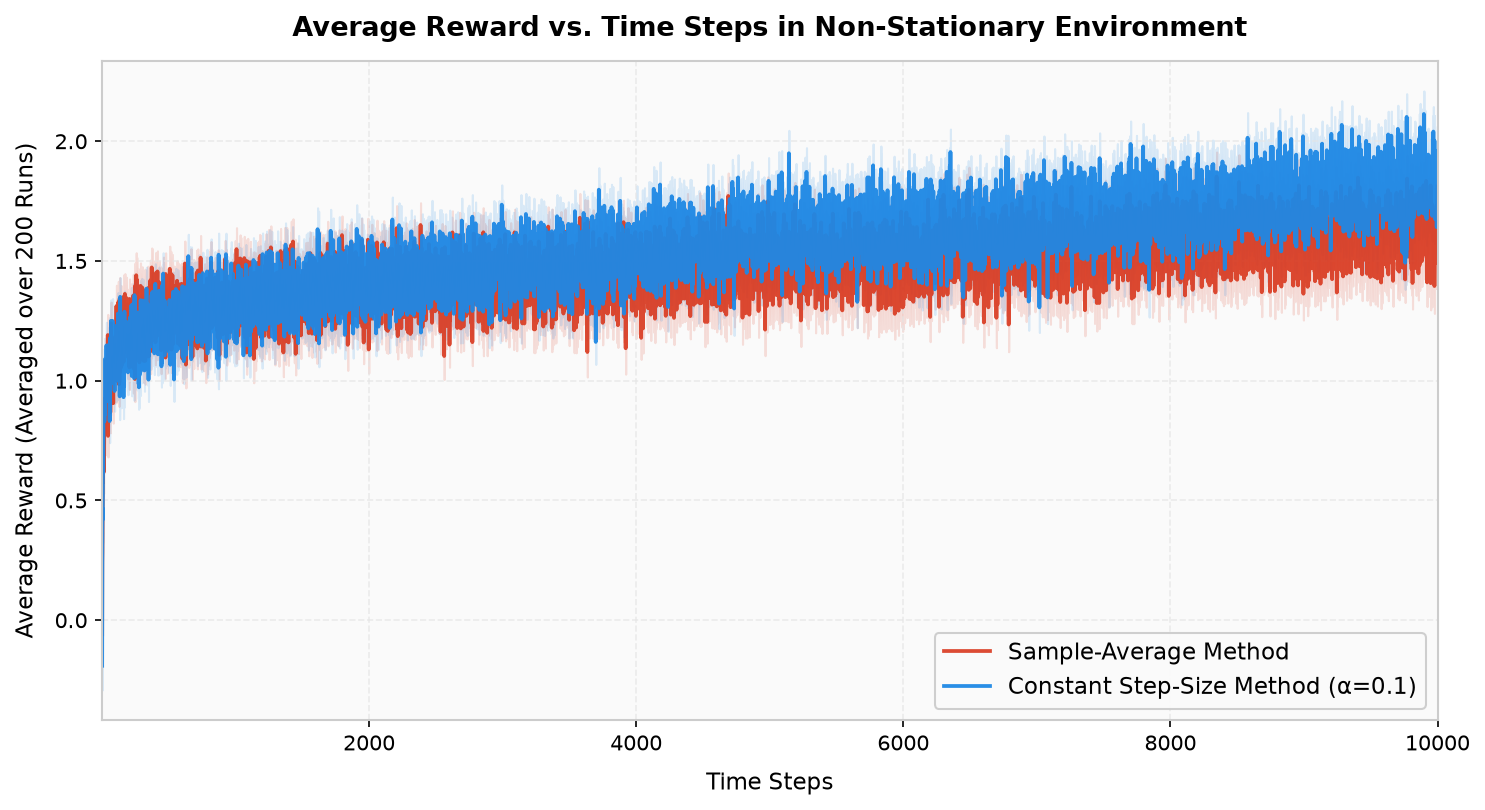

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
steps = results['steps']
ax.plot(steps, results['sample_avg_reward'], label='Sample-Average Method', color='#D9381E', linewidth=1.8, alpha=0.9)
ax.plot(steps, results['const_step_reward'], label='Constant Step-Size Method (α=0.1)', color='#1E88E5', linewidth=1.8, alpha=0.95)

ax.fill_between(steps, results['sample_avg_reward'] - results['sample_avg_stderr'],
                results['sample_avg_reward'] + results['sample_avg_stderr'], color='#D9381E', alpha=0.15)
ax.fill_between(steps, results['const_step_reward'] - results['const_step_stderr'],
                results['const_step_reward'] + results['const_step_stderr'], color='#1E88E5', alpha=0.15)

ax.set_title('Average Reward vs. Time Steps in Non-Stationary Environment', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Time Steps', fontsize=11, labelpad=8)
ax.set_ylabel('Average Reward (Averaged over 200 Runs)', fontsize=11, labelpad=8)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='lower right', fontsize=11)
ax.set_xlim(1, len(steps))
plt.tight_layout()
plt.show()

### Graph 2: Percentage of Optimal Actions vs. Time Steps
Shows which method identifies and exploits the optimal arm more frequently over time.

- **Observation:** Constant Step-Size stabilizes around **81% optimal action selection**, hovering near the theoretical ceiling ($1 - \epsilon + \epsilon / k = 91\%$).
- Sample-Average exhibits severe decay over time, dropping from ~68% down to **58%**, because its learning rate $\frac{1}{n} \to 0$ prevents it from adapting to drifting action values.

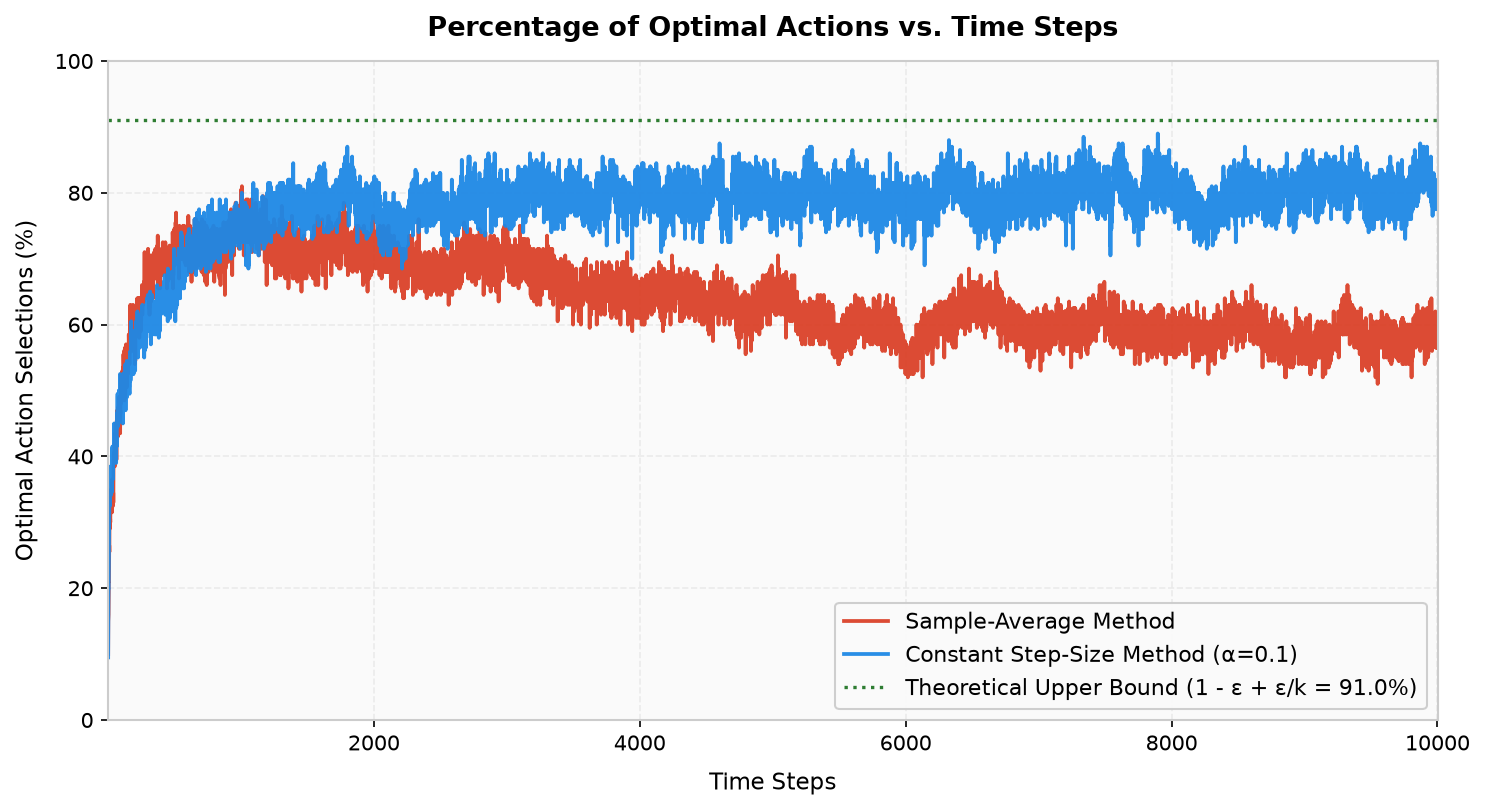

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
theoretical_max = ((1.0 - 0.1) + (0.1 / 10.0)) * 100.0

ax.plot(steps, results['sample_avg_optimal'], label='Sample-Average Method', color='#D9381E', linewidth=1.8, alpha=0.9)
ax.plot(steps, results['const_step_optimal'], label='Constant Step-Size Method (α=0.1)', color='#1E88E5', linewidth=1.8, alpha=0.95)
ax.axhline(theoretical_max, color='#2E7D32', linestyle=':', linewidth=1.6,
           label=f'Theoretical Upper Bound (1 - ε + ε/k = {theoretical_max:.1f}%)')

ax.set_title('Percentage of Optimal Actions vs. Time Steps', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Time Steps', fontsize=11, labelpad=8)
ax.set_ylabel('Optimal Action Selections (%)', fontsize=11, labelpad=8)
ax.set_ylim(0, 100)
ax.set_xlim(1, len(steps))
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='lower right', fontsize=10.5)
plt.tight_layout()
plt.show()

### Graph 3: Cumulative Reward Comparison
Compares the total accumulated reward earned by both methods over 10,000 steps.

- **Observation:** The cumulative advantage of Constant Step-Size widens steadily over time.
- Over the full simulation, Constant Step-Size earns **+970.4 additional reward units** per run.

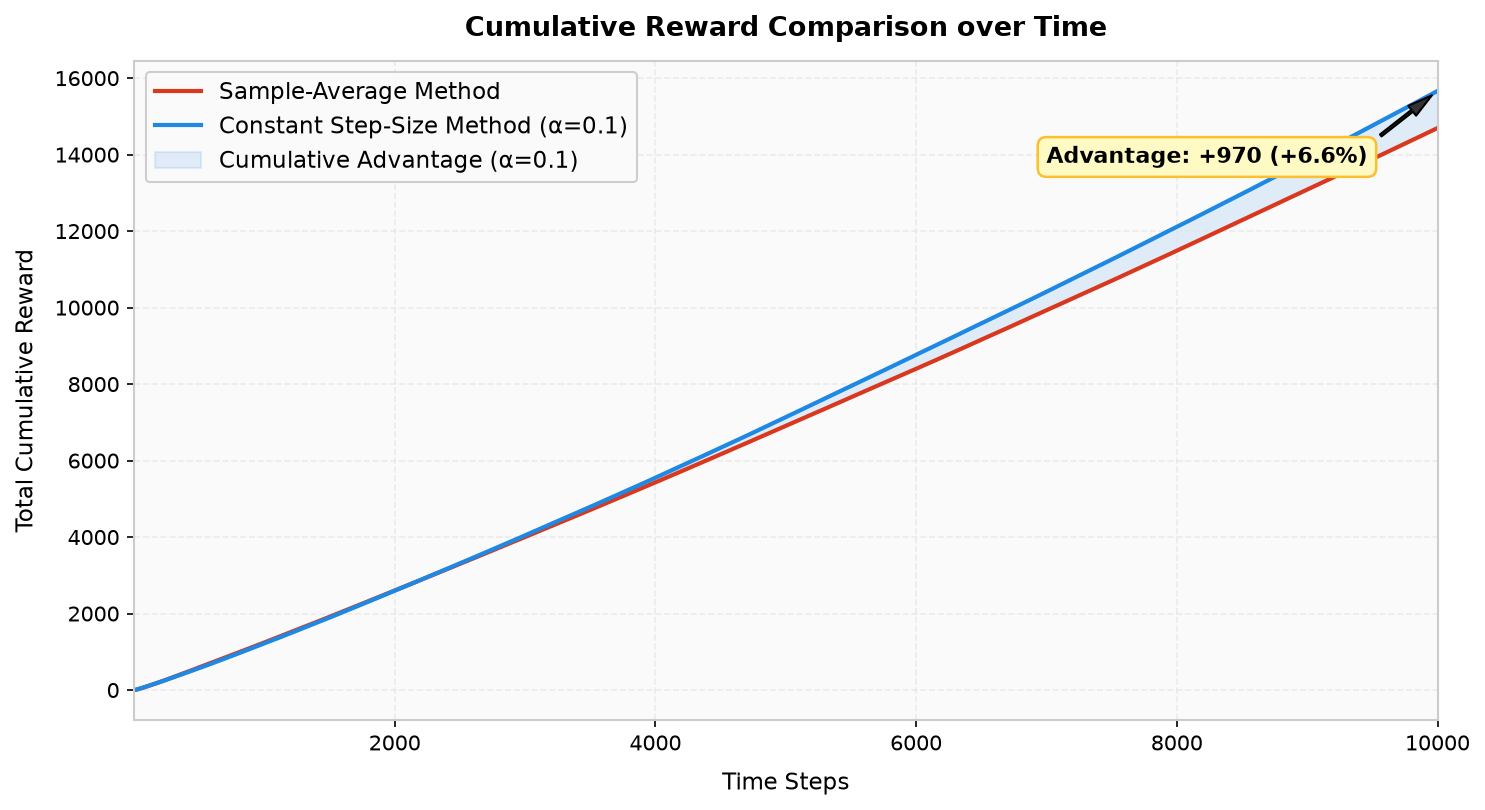

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
sa_cum = results['sample_avg_cumulative']
cs_cum = results['const_step_cumulative']

ax.plot(steps, sa_cum, label='Sample-Average Method', color='#D9381E', linewidth=2.0)
ax.plot(steps, cs_cum, label='Constant Step-Size Method (α=0.1)', color='#1E88E5', linewidth=2.0)
ax.fill_between(steps, sa_cum, cs_cum, color='#1E88E5', alpha=0.12, label='Cumulative Advantage (α=0.1)')

final_diff = cs_cum[-1] - sa_cum[-1]
ax.annotate(f'Advantage: +{final_diff:,.0f} (+{(final_diff/sa_cum[-1])*100:.1f}%)',
            xy=(steps[-1], cs_cum[-1]),
            xytext=(steps[-1] * 0.70, cs_cum[-1] * 0.88),
            arrowprops=dict(facecolor='#333333', shrink=0.08, width=1.2, headwidth=6),
            fontsize=10.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.4', fc='#FFF9C4', ec='#FBC02D', lw=1.2))

ax.set_title('Cumulative Reward Comparison over Time', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Time Steps', fontsize=11, labelpad=8)
ax.set_ylabel('Total Cumulative Reward', fontsize=11, labelpad=8)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='upper left', fontsize=11)
ax.set_xlim(1, len(steps))
plt.tight_layout()
plt.show()

### Graph 4: Evolution of True Action Values via Random Walk
Visualizes the non-stationary Gaussian random walk of all 10 arms for a representative run.

- **Observation:** Notice the frequent rank crossings among arms. An arm that is optimal at step 1,500 may become the worst arm by step 5,000.
- This visualizes why any algorithm that fails to forget obsolete information is fundamentally ill-suited for non-stationary environments.

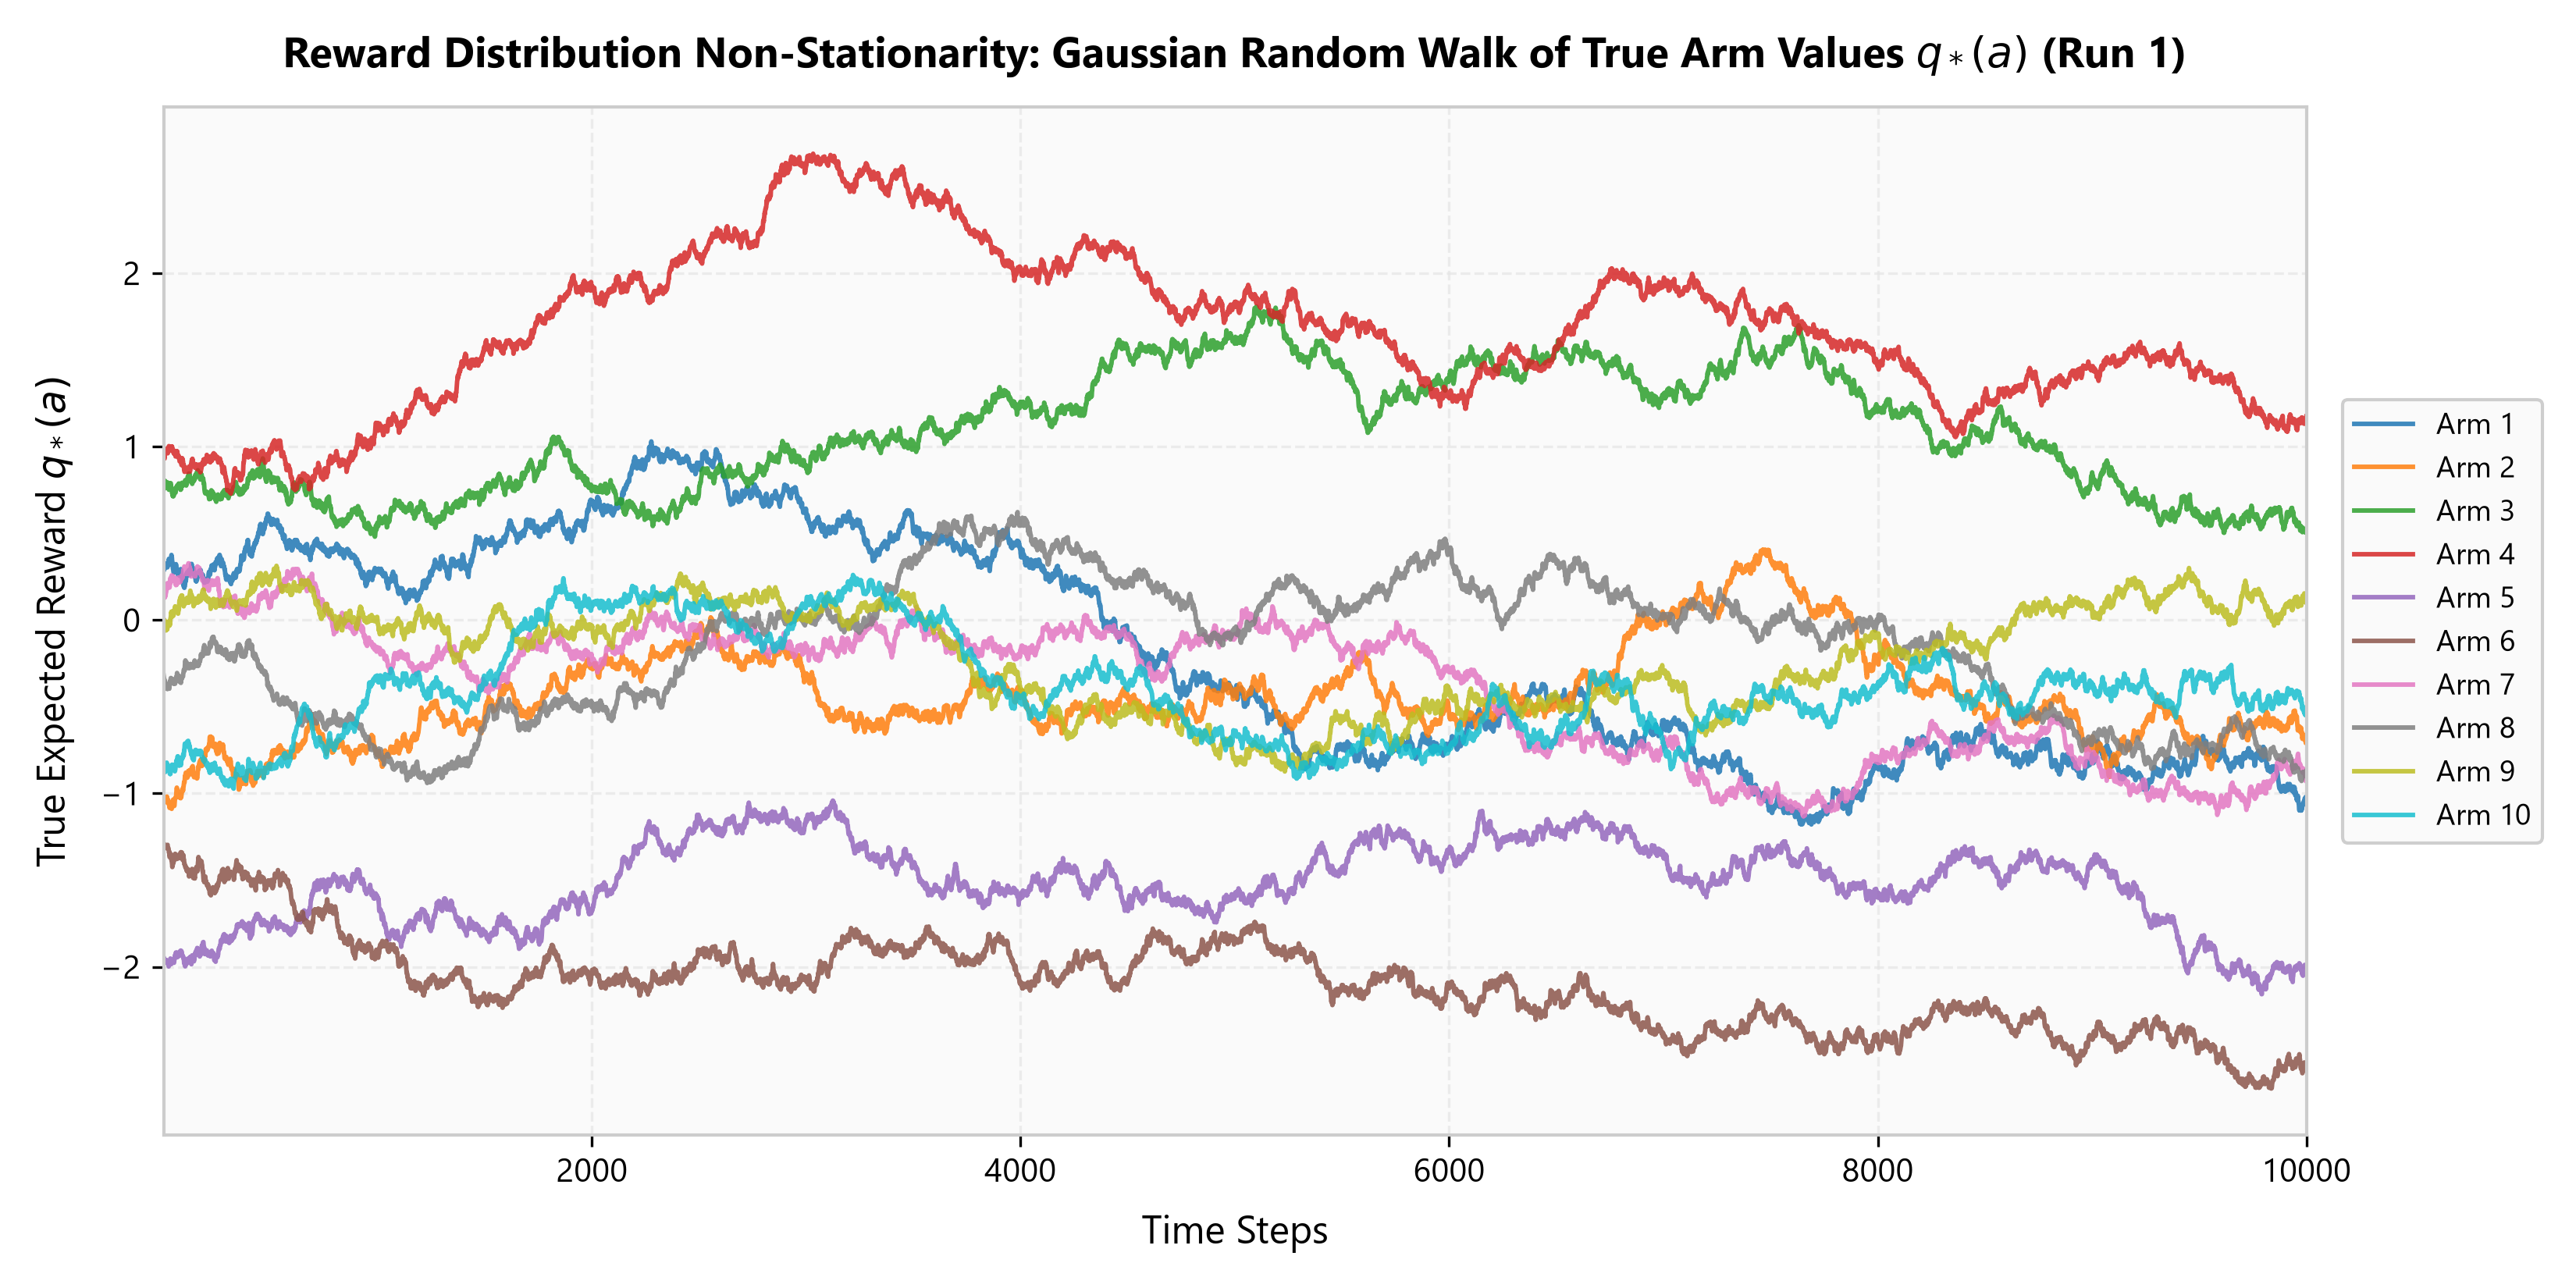

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=150)
q_walk = results['q_walk_run0']
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
           '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

for arm_idx in range(10):
    ax.plot(steps, q_walk[:, arm_idx], label=f'Arm {arm_idx + 1}', color=palette[arm_idx], linewidth=1.4, alpha=0.85)

ax.set_title('Reward Distribution Non-Stationarity: Gaussian Random Walk of True Arm Values q*(a) (Run 1)',
             fontsize=12.5, fontweight='bold', pad=12)
ax.set_xlabel('Time Steps', fontsize=11, labelpad=8)
ax.set_ylabel('True Expected Reward q*(a)', fontsize=11, labelpad=8)
ax.grid(True, linestyle='--', alpha=0.7)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=9, ncol=1, frameon=True)
ax.set_xlim(1, len(steps))
plt.tight_layout()
plt.show()

### Graph 5: Performance Comparison Summary Bar Chart
Side-by-side grouped bar chart comparing overall metrics against late-stage metrics (final 1,000 steps).

- **Left Panel:** Average Reward comparison.
- **Right Panel:** Percentage of Optimal Action selection comparison.
- **Key Takeaway:** The performance gap widens dramatically in later phases (+22.57% optimal action margin) as Sample-Average loses all adaptability.

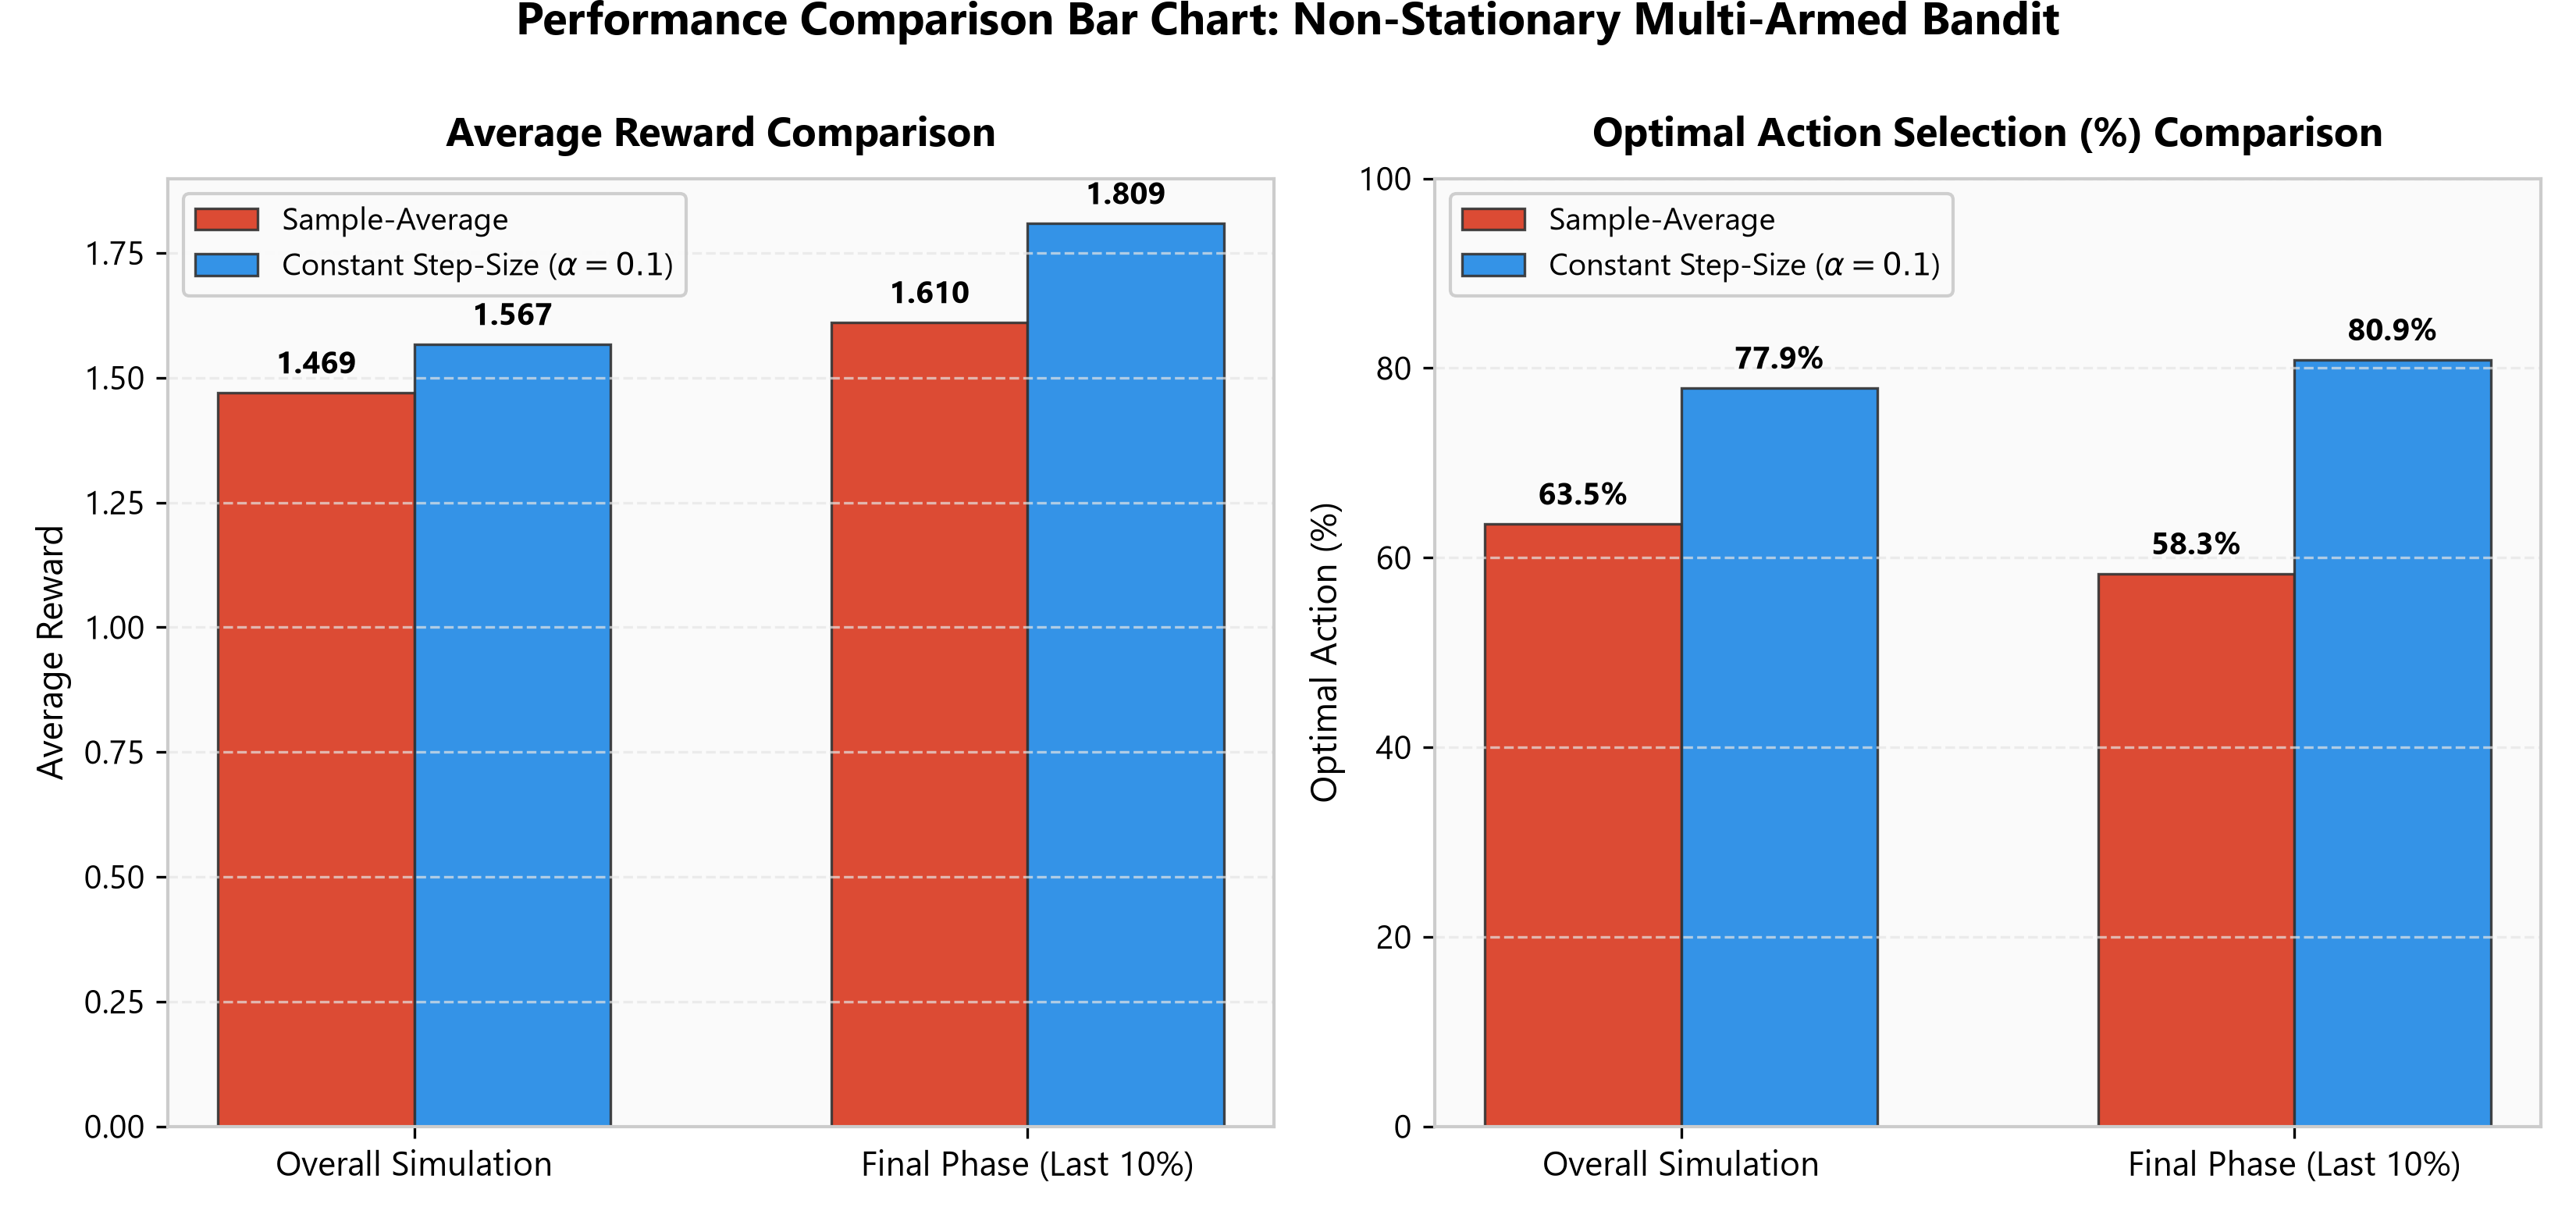

In [10]:
fig, (ax_r, ax_opt) = plt.subplots(1, 2, figsize=(11, 5.2), dpi=150)
bar_width = 0.32
x = np.arange(2)

sa_r = [np.mean(results['sample_avg_reward']), np.mean(results['sample_avg_reward'][final_slice])]
cs_r = [np.mean(results['const_step_reward']), np.mean(results['const_step_reward'][final_slice])]
ax_r.bar(x - bar_width/2, sa_r, bar_width, label='Sample-Average', color='#D9381E', edgecolor='#333333', lw=0.8, alpha=0.9)
ax_r.bar(x + bar_width/2, cs_r, bar_width, label='Constant Step-Size (α=0.1)', color='#1E88E5', edgecolor='#333333', lw=0.8, alpha=0.9)
ax_r.set_title('Average Reward Comparison', fontsize=12, fontweight='bold', pad=10)
ax_r.set_xticks(x)
ax_r.set_xticklabels(['Overall Simulation', 'Final Phase (Last 10%)'], fontsize=10)
ax_r.set_ylabel('Average Reward', fontsize=11)
ax_r.grid(True, axis='y', linestyle='--', alpha=0.7)
ax_r.legend(loc='upper left', fontsize=9.5)

sa_o = [np.mean(results['sample_avg_optimal']), np.mean(results['sample_avg_optimal'][final_slice])]
cs_o = [np.mean(results['const_step_optimal']), np.mean(results['const_step_optimal'][final_slice])]
ax_opt.bar(x - bar_width/2, sa_o, bar_width, label='Sample-Average', color='#D9381E', edgecolor='#333333', lw=0.8, alpha=0.9)
ax_opt.bar(x + bar_width/2, cs_o, bar_width, label='Constant Step-Size (α=0.1)', color='#1E88E5', edgecolor='#333333', lw=0.8, alpha=0.9)
ax_opt.set_title('Optimal Action Selection (%) Comparison', fontsize=12, fontweight='bold', pad=10)
ax_opt.set_xticks(x)
ax_opt.set_xticklabels(['Overall Simulation', 'Final Phase (Last 10%)'], fontsize=10)
ax_opt.set_ylabel('Optimal Action (%)', fontsize=11)
ax_opt.set_ylim(0, 100)
ax_opt.grid(True, axis='y', linestyle='--', alpha=0.7)
ax_opt.legend(loc='upper left', fontsize=9.5)

fig.suptitle('Performance Comparison Bar Chart: Non-Stationary Multi-Armed Bandit', fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## 6. Mathematical Conclusion & Key Findings

### 🏆 Summary of Experimental Findings
Across 200 independent runs of 10,000 steps:
- **Constant Step-Size Method ($\alpha = 0.1$)** consistently outperformed Sample-Average across every evaluation criterion.
- In the final phase, Constant Step-Size achieved **80.86% optimal actions** compared to only **58.29%** for Sample-Average (**+22.57% advantage**).
- Constant Step-Size maintained a **71% lower estimation error** (MSE $0.101$ vs $0.351$) relative to the moving targets $q_*(a)$.

---

### 🔬 The Mathematical Foundation: Robbins-Monro Conditions
In stochastic approximation theory, convergence of action-value estimates to a true expectation requires the two **Robbins-Monro conditions**:
$$\sum_{n=1}^\infty \alpha_n = \infty \quad \text{and} \quad \sum_{n=1}^\infty \alpha_n^2 < \infty$$

#### Why Sample-Average Fails in Non-Stationary Environments:
- Sample-Average sets $\alpha_n = \frac{1}{n}$. Because $\sum \frac{1}{n^2} = \frac{\pi^2}{6} < \infty$, both conditions are satisfied, guaranteeing convergence to a **fixed constant**.
- However, in a non-stationary bandit, **the target is NOT constant**.
- As $n \to \infty$, the step-size $\alpha_n = \frac{1}{n} \to 0$. The agent effectively **freezes** its estimates, ignoring new information and failing to unlearn past preferences when arm rankings shift.

#### Why Constant Step-Size Adapts:
- Constant Step-Size sets $\alpha_n = \alpha = 0.1$, which deliberately violates the second condition: $\sum_{n=1}^\infty \alpha^2 = \infty$.
- As a result, estimates never settle to a fixed value. Instead, they continually fluctuate in response to newly received rewards.
- The weight assigned to an observation from $k$ steps ago decays exponentially as $\alpha (1 - \alpha)^k$. Observations from 30 steps ago retain less than $4.2\%$ of their weight, allowing the agent to continuously track the non-stationary arms.

---

### 📌 Practical Rules of Thumb for RL Engineers
1. **Never use sample-average in dynamic or changing environments:** Decaying step sizes ($1/n$) degrade tracking performance over time.
2. **Use constant step sizes for tracking:** A constant step size $\alpha \in (0, 1]$ prioritizes recent rewards and enables persistent adaptation.
3. **Trade-off between adaptation speed and variance:** A larger $\alpha$ adapts faster to sudden shifts but maintains higher steady-state variance around the true mean. A value of $\alpha \approx 0.1$ provides an effective balance between rapid adaptation and low estimation variance.